# **Google Landmarks Places**

**Цель**: изучить структуру и качество данных о достопримечательностях, а также определить, насколько такой набор данных может быть полезен для проекта.

> **Ограничение:** Google Landmarks Places представляет собой каталог географических объектов, а не набор коротких видеороликов из социальных сетей. Поэтому он позволяет исследовать структуру справочника POI (Points of Interest — значимых точек интереса), но не позволяет непосредственно оценить извлечение названий мест из описаний Reels, распознавание речи, субтитров или текста на изображении.
Результаты исследования следует рассматривать как анализ вспомогательного источника географических данных. Для непосредственной оценки алгоритмов извлечения мест потребуется отдельная размеченная выборка видеороликов.

Источник: `visheratin/google_landmarks_places` на Hugging Face. В карточке указаны около 35 тыс. строк и поля `id`, `category_name`, `name`, `lat`, `lon`, `city`, `state`, `country`.


## 1. Загрузка данных
На первом этапе загружаем датасет из Hugging Face и сохраняем его в объект df библиотеки pandas. Далее проверяем, удалось ли получить данные, и просматриваем первые строки таблицы.

Первичный просмотр необходим, чтобы убедиться, что источник доступен, данные прочитаны корректно и таблица содержит ожидаемые поля.

Если загрузка завершается ошибкой, последующие этапы анализа выполнять нельзя, пока проблема не будет устранена. Причиной может быть недоступность источника, ошибка в адресе файла или отсутствие библиотеки для чтения формата Parquet.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_URL = "https://huggingface.co/datasets/visheratin/google_landmarks_places/resolve/main/data/train-00000-of-00001-115411102ff03bc7.parquet"

try:
    df = pd.read_parquet(DATA_URL)
    print("Данные загружены. Размер:", df.shape)
    display(df.head())
except Exception as e:
    print("Ошибка загрузки:", repr(e))
    print("Если указано, что отсутствует Parquet engine, выполните: %pip install -q pyarrow")
    print("Если timeout, проверьте доступность huggingface.co из Colab.")


Данные загружены. Размер: (35070, 8)


,id,category_name,name,lat,lon,city,state,country
0,0,Category:Happy_Valley_Racecourse,Natural Turf Soccer Pitch No. 5,22.272800,114.182000,Hong Kong Island,Hong Kong,China
1,1,Category:Luitpoldpark_in_Munich,,48.171494,11.569674,Munich,Bavaria,Germany
2,3,"Category:Tweed_Heads,_New_South_Wales",Ukerebagh Nature Reserve,-28.183300,153.550000,Tweed Heads,New South Wales,Australia
3,14,Category:Delacorte_Theater,Delacorte Theater,40.780100,-73.968767,New York,New York,United States
4,15,Category:Tremper_Mound_and_Earthworks,Tremper Mound,38.801300,-83.010600,,Ohio,United States


## 2. Структура данных

На этом этапе исследуем базовую структуру набора данных: количество строк и столбцов, названия признаков и типы данных.

Каждая строка представляет отдельную запись каталога. В зависимости от фактической схемы датасета признаки могут включать идентификатор объекта, его название, категорию, координаты, город, регион и страну.

Проверка типов данных позволяет выявить признаки, которые требуют дополнительного преобразования. Например, координаты должны быть представлены числовыми значениями, чтобы их можно было использовать в географическом анализе.

**Что необходимо зафиксировать в результатах:**

* количество записей и признаков;

* назначение наиболее важных столбцов;

* наличие неожиданных типов данных;

* достаточность имеющихся признаков для последующего анализа.

In [2]:
print("Строк:", len(df), "| Столбцов:", len(df.columns))
print("Столбцы:", df.columns.tolist())
display(df.dtypes.to_frame("dtype"))
display(df.head(10))


Строк: 35070 | Столбцов: 8
Столбцы: ['id', 'category_name', 'name', 'lat', 'lon', 'city', 'state', 'country']


,dtype
id,int64
category_name,object
name,object
lat,float64
lon,float64
city,object
state,object
country,object


,id,category_name,name,lat,lon,city,state,country
0,0,Category:Happy_Valley_Racecourse,Natural Turf Soccer Pitch No. 5,22.272800,114.182000,Hong Kong Island,Hong Kong,China
1,1,Category:Luitpoldpark_in_Munich,,48.171494,11.569674,Munich,Bavaria,Germany
2,3,"Category:Tweed_Heads,_New_South_Wales",Ukerebagh Nature Reserve,-28.183300,153.550000,Tweed Heads,New South Wales,Australia
3,14,Category:Delacorte_Theater,Delacorte Theater,40.780100,-73.968767,New York,New York,United States
4,15,Category:Tremper_Mound_and_Earthworks,Tremper Mound,38.801300,-83.010600,,Ohio,United States
5,19,Category:Andover_Canal,Anton Mill Road North Car Park,51.204490,-1.481780,Test Valley,England,United Kingdom
6,22,Category:Castle_of_Santa_Cruz,Santa Cruz Castle,43.348300,-8.350000,Santa Cruz,Galicia,Spain
7,25,Category:Sant_Julià_de_Pedra,Sant Julià de Pedra,42.345000,1.810556,Bellver de Cerdanya,Catalonia,Spain
8,31,Category:St._Nikolaus_(Überlingen),Münster St. Nikolaus,47.767222,9.160556,Überlingen,Baden-Württemberg,Germany
9,37,"Category:Church_of_Saint_Stephen,_Prague",Saint Stephen,50.076361,14.424889,Prague,Prague,Czechia


## 3. Пропуски

Пропущенные значения — одна из основных проблем, которая может снижать качество географического справочника.

Для каждого столбца рассчитываем количество пропусков и их долю от общего числа записей. Это позволяет определить, какие атрибуты представлены достаточно полно, а какие могут отсутствовать у значительной части объектов.

**В контексте нашего проекта особенно важны:**

* название достопримечательности — необходимо для сопоставления с упоминаниями в видео;

* координаты — нужны для отображения объектов на карте и построения маршрута;

* страна и город — помогают ограничивать географию поиска;

* категория — позволяет классифицировать объекты и фильтровать результаты.

Пропуск необязательно означает ошибку в исходных данных. Например, некоторые объекты могут не иметь указанного города. Однако отсутствие координат или названия может затруднить использование соответствующей записи.

При интерпретации результатов учитываем не только количество пропусков, но и то, насколько критично отсутствие конкретного признака для задач проекта.

In [14]:
text_columns = ["category_name", "name", "city", "state", "country"]

missing_count = {}
missing_pct = {}

for col in df.columns:
    if col in text_columns:
        empty = (
            df[col].isna()
            | df[col].astype("string").str.strip().eq("").fillna(False)
        )
    else:
        empty = df[col].isna()

    missing_count[col] = int(empty.sum())
    missing_pct[col] = round(empty.mean() * 100, 2)

missing_df = pd.DataFrame({
    "missing_count": missing_count,
    "missing_pct": missing_pct
})

display(missing_df)


,missing_count,missing_pct
id,0,0.00
category_name,0,0.00
name,7657,21.83
lat,0,0.00
lon,0,0.00
city,3329,9.49
state,4877,13.91
country,0,0.00


## 4. Дубликаты и идентификаторы

Дубликаты могут возникать при объединении источников, повторной выгрузке данных или особенностях формирования каталога. Они способны искажать статистику: например, завышать количество объектов в отдельных категориях или городах.

В рамках анализа проверяем два вида повторов:

1. Полностью одинаковые строки — записи, у которых совпадают все значения признаков.

2. Повторяющиеся идентификаторы — строки, которым присвоен одинаковый id.

Эти проверки не равнозначны. Повторяющийся идентификатор не обязательно означает, что строки полностью совпадают: у них могут различаться отдельные атрибуты. Такие случаи требуют дополнительной проверки.

Для системы построения маршрутов качество идентификации объектов особенно важно: один и тот же объект не должен ошибочно восприниматься как несколько разных достопримечательностей.

По результатам фиксируем количество найденных повторов и при наличии дубликатов изучаем несколько примеров, прежде чем делать вывод о необходимости очистки данных.

In [4]:
print("Полностью дублирующихся строк:", int(df.duplicated().sum()))
if "id" in df.columns:
    print("Строк с повторяющимся id:", int(df["id"].duplicated().sum()))
    display(df[df["id"].duplicated(keep=False)].sort_values("id").head(20))
for col in ["name", "category_name"]:
    if col in df.columns:
        s = df[col].astype("string").str.strip()
        print(f"Пустые значения {col} (NaN или пустая строка):", int((s.isna() | s.eq("")).sum()))


Полностью дублирующихся строк: 0
Строк с повторяющимся id: 0


,id,category_name,name,lat,lon,city,state,country


Пустые значения name (NaN или пустая строка): 7657
Пустые значения category_name (NaN или пустая строка): 0


## 5. Проверка координат

Географические координаты — один из ключевых атрибутов для проекта, поскольку они позволяют определять положение достопримечательностей на карте и рассчитывать порядок посещения точек.

Широта должна находиться в диапазоне от −90 до 90 градусов, а долгота — от −180 до 180 градусов. Значения за пределами этих диапазонов считаются некорректными.

**В ходе анализа проверяем:**

* наличие широты и долготы одновременно;

* долю записей с координатами;

* соответствие координат допустимым диапазонам;

* основные статистические характеристики координат.

Важно различать отсутствие координат и наличие некорректных значений. В первом случае географическое положение объекта не указано, во втором — данные требуют проверки.

Даже координаты, находящиеся в допустимых диапазонах, не обязательно соответствуют реальному местоположению объекта. Поэтому проведённую проверку рассматриваем как базовый контроль качества, а не как полную верификацию географической точности.

In [5]:
df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
valid_coords = df["lat"].between(-90, 90) & df["lon"].between(-180, 180)
both_present = df[["lat", "lon"]].notna().all(axis=1)
print("Обе координаты заполнены:", int(both_present.sum()))
print("Координаты в допустимом диапазоне:", int(valid_coords.sum()))
print("Координаты вне диапазона среди заполненных:", int((both_present & ~valid_coords).sum()))
display(df[["lat", "lon"]].describe().T)


Обе координаты заполнены: 35070
Координаты в допустимом диапазоне: 35070
Координаты вне диапазона среди заполненных: 0


,count,mean,std,min,25%,50%,75%,max
lat,35070.0,41.678038,18.026887,-55.98,38.897311,46.506785,51.393042,82.216667
lon,35070.0,5.136603,60.466079,-179.40,-3.057512,9.221720,18.013715,179.047000


## 6. Страны

На этом этапе изучаем распределение объектов по странам. Анализ позволяет понять, какие территории представлены в каталоге наиболее широко и насколько географически разнообразен набор данных.

Рассчитываем количество записей для каждой страны, определяем число различных значений поля `country` и рассматриваем наиболее представленные страны.

При интерпретации учитываем, что количество записей в стране не обязательно отражает реальное количество достопримечательностей. Оно также зависит от принципов формирования исходного датасета и полноты сбора данных.

Для нашего проекта географическое покрытие важно потому, что пользователь может захотеть построить маршрут по конкретной стране или региону. Если определённая территория представлена слабо, система может не найти нужные объекты даже при корректном алгоритме поиска.

Уникальных стран: 193


,poi_count
country,
United States,5090
Germany,4079
United Kingdom,2979
Italy,2759
France,2652
Japan,1492
Spain,1241
Poland,1226
Sweden,1100


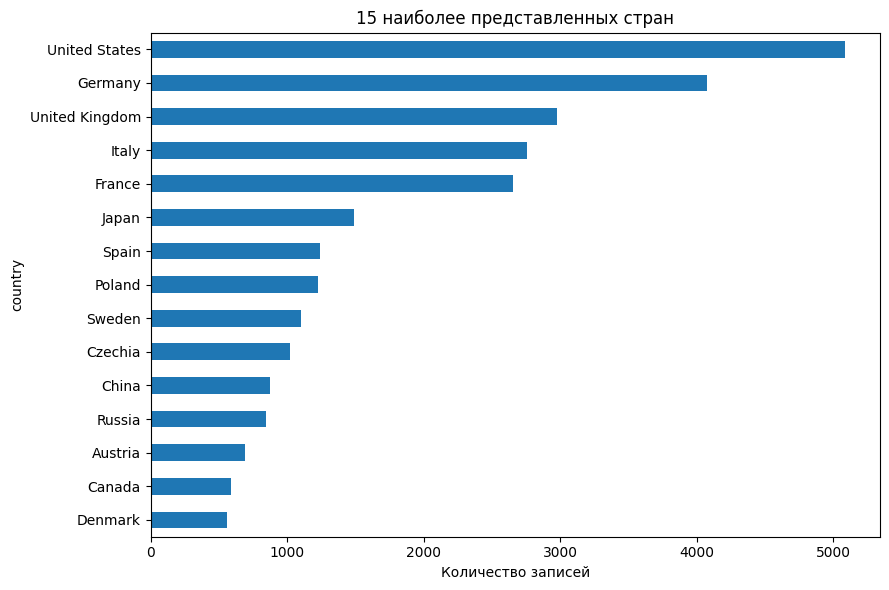

In [6]:
countries = df["country"].fillna("Не указано").replace("", "Не указано").value_counts()
print("Уникальных стран:", df["country"].nunique(dropna=True))
display(countries.head(20).rename_axis("country").to_frame("poi_count"))
countries.head(15).sort_values().plot(kind="barh", figsize=(9,6), title="15 наиболее представленных стран")
plt.xlabel("Количество записей"); plt.tight_layout(); plt.show()


## 7. Города и регионы

Страна задаёт крупную географическую область, однако для формирования туристического маршрута часто требуется более точная локализация.

Поэтому отдельно анализируем поля `city` и `state`. Для каждого поля оцениваем количество заполненных записей, долю заполненности и число уникальных значений.

Высокая заполненность города может упростить группировку достопримечательностей и поиск объектов внутри одной поездки. Отсутствие города не всегда делает запись бесполезной: при наличии корректных координат объект всё ещё можно разместить на карте.

При этом уникальные значения могут включать варианты написания одного и того же названия. В базовом EDA мы подсчитываем значения буквально, не выполняя нормализацию названий и не объединяя синонимы.

Результаты помогут определить, насколько удобно использовать географические поля для фильтрации POI и формирования маршрутов в пределах города или региона.

In [7]:
for col in ["city", "state"]:
    s = df[col].fillna("").astype(str).str.strip()
    nonempty = s[s.ne("")]
    print(f"{col}: заполнено {len(nonempty)}/{len(df)} ({len(nonempty)/max(len(df),1):.1%}); уникальных значений: {nonempty.nunique()}")
    display(nonempty.value_counts().head(15).rename_axis(col).to_frame("poi_count"))


city: заполнено 31741/35070 (90.5%); уникальных значений: 12539


,poi_count
city,
Rome,422
Paris,366
Berlin,359
London,329
New York,317
Florence,271
Prague,236
Vienna,235
Moscow,232


state: заполнено 30193/35070 (86.1%); уникальных значений: 1095


,poi_count
state,
England,2112
North Rhine-Westphalia,777
Scotland,669
Tuscany,627
California,546
Bavaria,542
Hong Kong,540
Baden-Württemberg,519
Ile-de-France,512


## 8. Категории

Поле `category_name` потенциально может содержать информацию для идентификации или классификации объектов. Однако прежде чем использовать его для тематической группировки достопримечательностей, необходимо проверить семантику значений. Поэтому на этом этапе мы изучаем количество уникальных значений и частоту их повторения, не предполагая заранее, что поле содержит обобщённые типы объектов.

На этом этапе рассчитываем количество записей по каждой категории, определяем число уникальных категорий и рассматриваем наиболее частые значения.

Распределение категорий помогает понять, какие типы объектов преобладают в датасете и насколько разнообразен его тематический состав.

Однако частота категории зависит от особенностей исходной разметки. Несколько похожих категорий могут обозначать близкие типы объектов, а некоторые записи могут не иметь категории.

В рамках текущего этапа мы описываем существующее распределение, но не объединяем категории и не оцениваем их семантическую согласованность.

**Практическая значимость:** если система в дальнейшем будет поддерживать тематические маршруты, качество и полнота категорий могут влиять на качество рекомендаций.

In [15]:
category_counts = df["category_name"].value_counts()

print("Уникальных значений category_name:",
      df["category_name"].nunique())

print("Категорий, встречающихся больше одного раза:",
      (category_counts > 1).sum())

print("Максимальная частота:",
      category_counts.max())

print("\nТоп-10 значений category_name:")
display(category_counts.head(10).to_frame("poi_count"))

Уникальных значений category_name: 35070
Категорий, встречающихся больше одного раза: 0
Максимальная частота: 1

Топ-10 значений category_name:


,poi_count
category_name,
Category:Hoa_Lu,1
Category:Happy_Valley_Racecourse,1
Category:Luitpoldpark_in_Munich,1
"Category:Tweed_Heads,_New_South_Wales",1
Category:Delacorte_Theater,1
Category:Tremper_Mound_and_Earthworks,1
Category:Andover_Canal,1
Category:Castle_of_Santa_Cruz,1
Category:Sant_Julià_de_Pedra,1


В датасете обнаружено 35 070 уникальных значений `category_name` — по одному на каждую запись. Повторяющихся значений нет.

Примеры значений, такие как `Category:Delacorte_Theater` и `Category:Luitpoldpark_in_Munich`, похожи на названия отдельных объектов, а не на обобщённые типы достопримечательностей. Это наблюдение не позволяет окончательно установить семантику поля, но показывает, что использовать его как готовую классификацию туристических мест без дополнительной проверки не следует.

Для проекта датасет может быть полезен для изучения географических характеристик объектов. При этом пригодность `category_name` для тематической фильтрации пока не подтверждена.

## 9. Названия POI

На этом этапе проверяем количество непустых названий, рассчитываем среднюю и медианную длину названия, а также изучаем распределение длины строк.

Длина названия сама по себе не является показателем его качества. Короткое название может быть вполне однозначным, тогда как длинное может содержать уточнения, альтернативные названия или дополнительные слова.

Тем не менее анализ позволяет обнаружить потенциально необычные записи: пустые строки, очень короткие названия или чрезмерно длинные значения, которые могут потребовать ручной проверки.

В дальнейшем для сопоставления POI с текстом из Reels могут понадобиться дополнительные методы: нормализация регистра и пунктуации, обработка вариантов написания, поиск по ключевым словам и семантическое сравнение текстов. В текущем EDA эти методы не реализуются, а рассматриваются как возможное направление развития проекта.

Записей с непустым названием: 27413
Средняя длина названия: 19.28
Медианная длина названия: 17.0


,id,category_name,city,state,country
1,1,Category:Luitpoldpark_in_Munich,Munich,Bavaria,Germany
11,54,Category:Karstadt_am_Bahnhof_(in_Munich),Munich,Bavaria,Germany
13,65,Category:John_Deere_House_and_Shop,Dixon,Illinois,United States
18,84,Category:Hindu_Temple_of_Atlanta,,Georgia,United States
23,124,Category:Szymbark_Castle,Szymbark,Warmian-Masurian Voivodeship,Poland
24,127,Category:B.W._Cooper_Projects,New Orleans,Louisiana,United States
25,131,Category:Shemokmedi_Cathedral,Shemokmedi,Guria,Georgia
30,168,Category:Ossiacher_See,Ostriach,Carinthia,Austria
42,248,Category:Tolshevskiy_Spaso-Preobrazhenskiy_Mon...,Voronezh,Voronezh Oblast,Russia
45,279,Category:Vadensjö_kyrka,Landskrona kommun,,Sweden


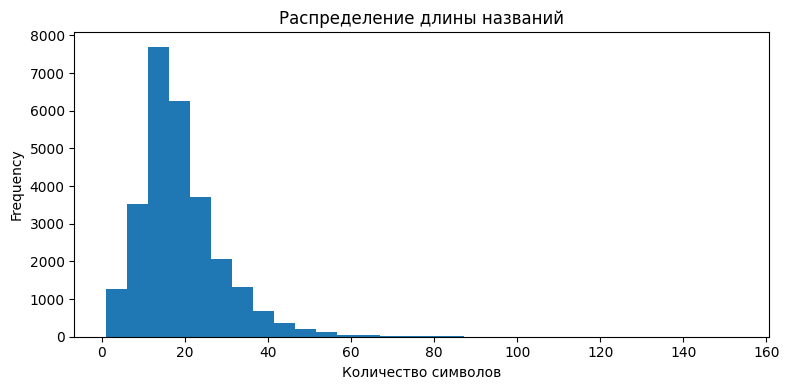

In [9]:
names = df["name"].fillna("").astype(str).str.strip()
lengths = names[names.ne("")].str.len()
print("Записей с непустым названием:", int(names.ne("").sum()))
print("Средняя длина названия:", round(lengths.mean(), 2) if len(lengths) else "нет данных")
print("Медианная длина названия:", round(lengths.median(), 2) if len(lengths) else "нет данных")
display(df.loc[names.eq(""), [c for c in ["id","category_name","city","state","country"] if c in df.columns]].head(15))
lengths.plot(kind="hist", bins=30, figsize=(8,4), title="Распределение длины названий")
plt.xlabel("Количество символов"); plt.tight_layout(); plt.show()


## 10. Географическая визуализация

Для наглядного представления географического покрытия строим диаграмму, на которой долгота откладывается по горизонтальной оси, а широта — по вертикальной.

Каждая точка соответствует одной записи с координатами, прошедшими базовую проверку диапазонов. Если количество записей велико, для визуализации используется случайная подвыборка фиксированного размера. Это ускоряет построение графика и делает его более читаемым.

Диаграмма позволяет увидеть общую географическую структуру данных и выявить возможные скопления точек или необычные распределения.

При этом график не является полноценной картой: на нём нет границ стран, береговых линий и подписей городов. Он предназначен для первичного анализа, а не для проверки точного расположения каждого объекта.

Следует также учитывать, что корректный диапазон координат не гарантирует географическую точность. Для более строгой проверки потребуется сопоставление с картографическим источником.

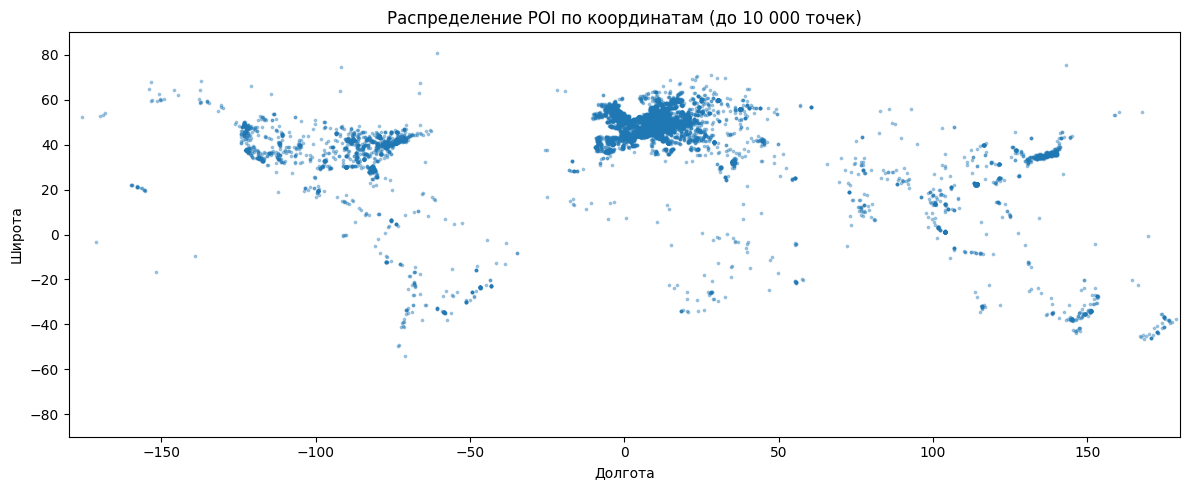

In [10]:
plot_df = df.loc[valid_coords, ["lat","lon"]].copy()
if len(plot_df) > 10000:
    plot_df = plot_df.sample(10000, random_state=42)
plt.figure(figsize=(12,5))
plt.scatter(plot_df["lon"], plot_df["lat"], s=3, alpha=.35)
plt.xlabel("Долгота"); plt.ylabel("Широта")
plt.title("Распределение POI по координатам (до 10 000 точек)")
plt.xlim(-180,180); plt.ylim(-90,90); plt.tight_layout(); plt.show()


## 11. Примеры записей

Количественные показатели помогают обнаружить общие закономерности, но не всегда объясняют причины выявленных проблем. Поэтому дополнительно рассматриваем несколько отдельных записей.

Случайная выборка позволяет оценить, насколько понятны названия объектов, согласуются ли между собой категория и географические поля, присутствуют ли подозрительные значения.

Этот этап является предварительной качественной проверкой. Он не заменяет полноценную ручную валидацию всего датасета, поскольку небольшая выборка может не содержать редких ошибок.

Если обнаруживаются подозрительные записи, необходимо привести конкретные примеры и указать, какие признаки вызывают сомнения. Не следует объявлять запись ошибочной только на основании необычного названия или отсутствия одного из необязательных полей.

In [11]:
display(df.sample(min(15, len(df)), random_state=42))

,id,category_name,name,lat,lon,city,state,country
28952,167725,Category:Gestas_(River),,44.902778,-0.315278,Vayres,Nouvelle-Aquitaine,France
34161,197923,Category:Sinagoga_del_Transito_(Toledo),Synagogue of El Tránsito,39.855722,-4.029444,Toledo,Castile-La Mancha,Spain
32177,186314,Category:Petřínská_rozhledna,Petrin Observation Tower,50.083544,14.395050,Prague,Prague,Czechia
1483,8531,Category:Château_de_Rosières,Château de Rosières,47.498600,5.403600,Saint-Seine-sur-Vingeanne,Bourgogne-Franche-Comté,France
27112,157076,Category:Wells_Cathedral,Wells Cathedral,51.210400,-2.643700,Wells,England,United Kingdom
6328,36750,Category:Flower_of_Life_(Memorial),Цветок жизни,59.995644,30.541098,,Leningrad oblast,Russia
5485,31918,Category:Ennis_House,Ennis House,34.116222,-118.292900,Los Angeles,California,United States
12093,69890,Category:Shrine_of_the_Báb,Shrine of the Bab,32.814444,34.987222,Haifa,Haifa District,Israel
4810,28047,Category:Kvikkjokks_kyrka,,66.951200,17.722100,Kvikkjokk,,Sweden
32740,189671,Category:Passage_Jouffroy_(Paris),Le petit roi,48.872549,2.342141,Paris,Ile-de-France,France


## 12. Применимость к проекту

После изучения структуры и качества данных оцениваем, какую роль каталог может выполнять в системе построения маршрутов по коротким видеороликам.

**Потенциальные преимущества:**

* Названия объектов могут использоваться для сопоставления с названиями мест, извлечёнными из видеороликов, если названия заполнены и достаточно информативны.
* Координаты позволяют размещать найденные объекты на карте и использовать их при построении маршрута.
* Страна и город могут применяться для ограничения области поиска. При этом город отсутствует в 9,49% записей, а регион — в 13,91%.
* Датасет охватывает 193 страны, что делает его потенциально полезным для географического поиска.

**Ограничения:**

В 21,83% записей отсутствует название объекта, что может затруднять сопоставление с упоминаниями в видео. Поле `category_name` содержит уникальное значение для каждой записи, поэтому его пригодность для классификации достопримечательностей не подтверждена.

Датасет не содержит необходимой разметки видеороликов, которая позволила бы проверить извлечение названий мест из подписей, речи, субтитров или визуального содержимого. По нему нельзя определить, насколько хорошо система распознаёт достопримечательности в Reels, обрабатывает несколько мест в одном видео или восстанавливает последовательность посещения.

Кроме того, наличие объекта в справочнике не гарантирует, что система сможет правильно сопоставить его с конкретным упоминанием. Для этого потребуются алгоритмы поиска и сопоставления, а также отдельная тестовая выборка с эталонными ответами.

Таким образом, датасет может рассматриваться как вспомогательный географический справочник POI, но не как самостоятельный набор для оценки всей системы извлечения мест и построения маршрутов.

## 13. Итоговые показатели

В последней аналитической ячейке собираем основные количественные показатели в единую таблицу. Это упрощает подготовку отчёта и позволяет сопоставить результаты отдельных этапов EDA.

В сводку включаем размер набора данных, число полностью дублирующихся строк, количество записей с корректными координатами и долю пропусков в ключевых полях.

Числа в сводной таблице должны использоваться вместе с результатами предыдущих разделов. Например, доля записей с координатами характеризует географическую полноту каталога, но не доказывает точность этих координат.

In [16]:
text_columns = ["category_name", "name", "city", "state", "country"]

missing_pct = {}

for col in df.columns:
    if col in text_columns:
        empty = (
            df[col].isna()
            | df[col].astype("string").str.strip().eq("").fillna(False)
        )
    else:
        empty = df[col].isna()

    missing_pct[f"{col}_missing_pct"] = round(
        empty.mean() * 100, 2
    )

summary = {
    "rows": len(df),
    "columns": df.shape[1],
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "valid_coordinate_rows": int(
        df["lat"].between(-90, 90).mul(
            df["lon"].between(-180, 180)
        ).sum()
    ),
}

summary.update(missing_pct)

summary_df = pd.DataFrame(
    {"value": summary}
)

display(summary_df)


,value
rows,35070.00
columns,8.00
exact_duplicate_rows,0.00
valid_coordinate_rows,35070.00
id_missing_pct,0.00
category_name_missing_pct,0.00
name_missing_pct,21.83
lat_missing_pct,0.00
lon_missing_pct,0.00
city_missing_pct,9.49


## 14. Выводы

В ходе исследовательского анализа был изучен набор Google Landmarks Places, содержащий 35 070 записей и 8 признаков. Датасет охватывает 193 страны и содержит географические координаты для всех записей. При этом 9,49% записей не имеют указанного города, 13,91% — региона, а в 21,83% отсутствует название объекта.

Полных дубликатов строк и повторяющихся идентификаторов не обнаружено. Все координаты находятся в допустимых диапазонах широты и долготы, однако их фактическая географическая точность в рамках данного исследования не проверялась.

Анализ `category_name` показал, что все значения уникальны. Поэтому использовать это поле для группировки объектов по тематическим типам без дополнительного изучения его семантики нельзя.

Полученные результаты показывают, что датасет потенциально пригоден для изучения географического покрытия и формирования вспомогательного справочника объектов. Вместе с тем пропуски названий и отсутствие разметки видеороликов ограничивают его возможности для непосредственной проверки алгоритмов извлечения мест из Reels.

Для дальнейшего развития проекта необходимо оценить качество сопоставления названий объектов с текстом из видеороликов и подготовить отдельную тестовую выборку с эталонными объектами и, при необходимости, последовательностью их посещения.